<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A013__%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота №13**

Багатокласова класифікація зображень за допомогою згорткових нейронних мереж (CNN) та перенесення навчання (Transfer Learning) на прикладі архітектури VGG16 у TensorFlow/Keras.

**ПІБ студента:** Надійко Роман                                 
**Група:** ФІТ 3-10                                                 
**Дата:** 25.11.2026

**Мета роботи**

Набути практичних навичок аналізу та підготовки наборів зображень, побудови й навчання власної згорткової нейронної мережі, а також донавчання (fine-tuning) попередньо навченої моделі VGG16 із підбором гіперпараметрів, застосуванням ранньої зупинки та візуальним аналізом кривих навчання і результатів класифікації.

1. Імпорт бібліотек та завантаження датасету з Kaggle

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)

# Завантаження датасету через kagglehub
import kagglehub
dataset_path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
print("Шлях до датасету:", dataset_path)

train_dir = os.path.join(dataset_path, "train")
valid_dir = os.path.join(dataset_path, "valid")
test_dir  = os.path.join(dataset_path, "test")

TensorFlow: 2.21.0
Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
Шлях до датасету: /kaggle/input/cards-image-datasetclassification


2. Аналіз та виведення даних

Кількість класів: 53
Всього зображень — Train: 7624, Valid: 265, Test: 265
Зображень на клас у train: мін = 108, макс = 181


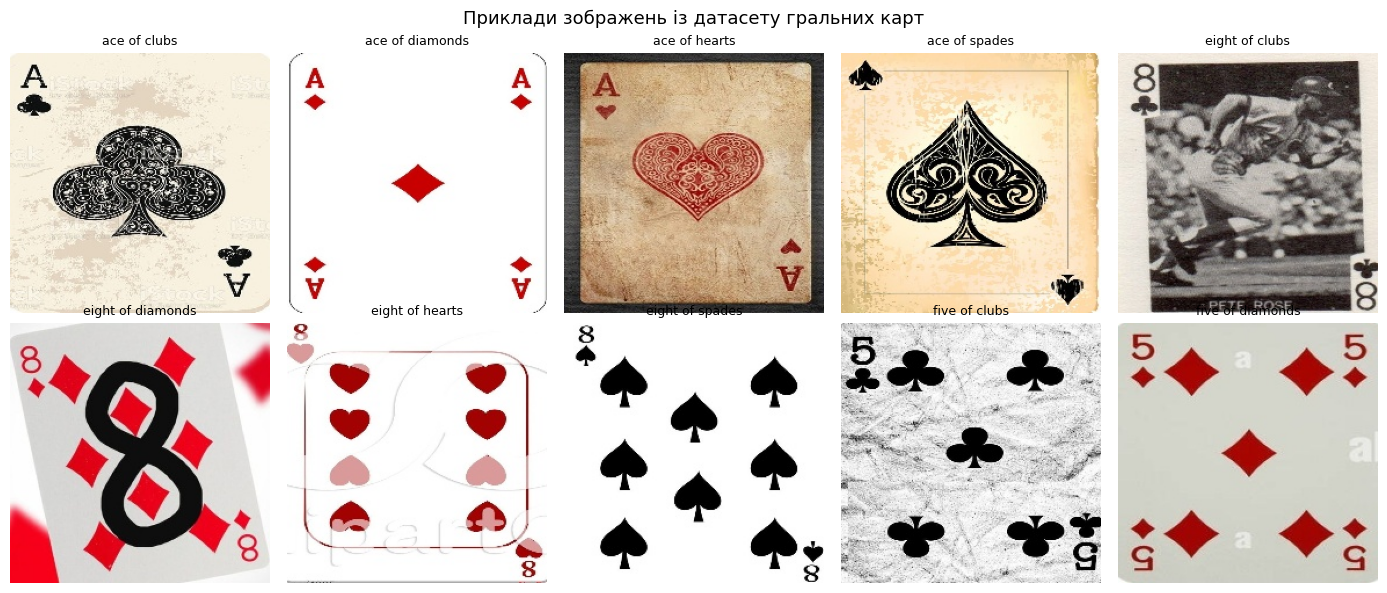

In [ ]:
# Підрахунок кількості зображень у кожній вибірці та класі
classes = sorted(os.listdir(train_dir))
num_classes = len(classes)

train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in classes}
valid_counts = {c: len(os.listdir(os.path.join(valid_dir, c))) for c in classes}
test_counts  = {c: len(os.listdir(os.path.join(test_dir, c)))  for c in classes}

print(f"Кількість класів: {num_classes}")
print(f"Всього зображень — Train: {sum(train_counts.values())}, Valid: {sum(valid_counts.values())}, Test: {sum(test_counts.values())}")
print(f"Зображень на клас у train: мін = {min(train_counts.values())}, макс = {max(train_counts.values())}")

# Візуалізація кількох прикладів із навчальної вибірки
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, cls_name in zip(axes.flat, classes[:10]):
    cls_folder = os.path.join(train_dir, cls_name)
    img_path = os.path.join(cls_folder, os.listdir(cls_folder)[0])
    img = keras.utils.load_img(img_path)
    ax.imshow(img)
    ax.set_title(cls_name, fontsize=9)
    ax.axis("off")

plt.suptitle("Приклади зображень із датасету гральних карт", fontsize=13)
plt.tight_layout()
plt.show()

3. Підготовка генераторів даних та аугментація

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42,
)

val_ds = keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

class_names = train_ds.class_names

# Оптимізація завантаження в пам'ять
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.prefetch(buffer_size=AUTOTUNE)

# Блок легкої аугментації даних для боротьби з перенавчанням
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.


4. Побудова та навчання власної згорткової моделі (Custom CNN) із підбором

In [ ]:
def build_custom_cnn(learning_rate=1e-3):
    model = keras.Sequential([
        keras.Input(shape=(224, 224, 3)),
        data_augmentation,
        layers.Rescaling(1.0 / 255.0),

        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.35),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ], name=f"custom_cnn_lr_{learning_rate}")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

# Швидкий підбір learning_rate по 2 епохи
best_lr = 1e-3
best_val_acc = 0.0

for lr in [1e-3, 5e-4]:
    print(f"\nПеревірка LR = {lr}:")
    tmp_model = build_custom_cnn(learning_rate=lr)
    h = tmp_model.fit(train_ds, validation_data=val_ds, epochs=2, verbose=1)
    val_acc = max(h.history["val_accuracy"])
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_lr = lr

print(f"\nОбрано learning_rate = {best_lr}")

cnn_model = build_custom_cnn(learning_rate=best_lr)
cnn_model.summary()

early_stop_cnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop_cnn],
    verbose=1,
)


Перевірка LR = 0.001:
Epoch 1/2
239/239 ━━━━━━━━━━━━━━━━━━━━ 32s 123ms/step - accuracy: 0.0639 - loss: 3.6413 - val_accuracy: 0.0226 - val_loss: 3.7609
Epoch 2/2
239/239 ━━━━━━━━━━━━━━━━━━━━ 29s 120ms/step - accuracy: 0.0829 - loss: 3.2973 - val_accuracy: 0.0792 - val_loss: 3.1422

Перевірка LR = 0.0005:
Epoch 1/2
239/239 ━━━━━━━━━━━━━━━━━━━━ 30s 118ms/step - accuracy: 0.0571 - loss: 3.7118 - val_accuracy: 0.0302 - val_loss: 3.8579
Epoch 2/2
239/239 ━━━━━━━━━━━━━━━━━━━━ 29s 121ms/step - accuracy: 0.0742 - loss: 3.3897 - val_accuracy: 0.0679 - val_loss: 3.1968

Обрано learning_rate = 0.001


Model: "custom_cnn_lr_0.001"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 53)             │         6,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,269 (458.08 KB)

 Trainable params: 116,821 (456.33 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 31s 120ms/step - accuracy: 0.0611 - loss: 3.5952 - val_accuracy: 0.0226 - val_loss: 4.0936
Epoch 2/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 28s 119ms/step - accuracy: 0.0792 - loss: 3.2930 - val_accuracy: 0.0415 - val_loss: 3.6030
Epoch 3/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 28s 119ms/step - accuracy: 0.0944 - loss: 3.2279 - val_accuracy: 0.0943 - val_loss: 3.1263
Epoch 4/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 28s 118ms/step - accuracy: 0.0986 - loss: 3.1586 - val_accuracy: 0.0491 - val_loss: 3.4612
Epoch 5/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 29s 119ms/step - accuracy: 0.1156 - loss: 3.1108 - val_accuracy: 0.0642 - val_loss: 3.1572
Epoch 6/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 28s 119ms/step - accuracy: 0.1120 - loss: 3.0747 - val_accuracy: 0.0528 - val_loss: 3.3701


5. Побудова та донавчання (Fine-Tuning) моделі VGG16

In [ ]:
# Завантаження попередньо навченої VGG16 (ImageNet) і навчання лише нової "голови" класифікатора
base_vgg = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_vgg.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_vgg(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

vgg_model = keras.Model(inputs, outputs, name="vgg16_cards")

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("\n Навчання верхніх шарів VGG16")
history_vgg_head = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1,
)

# Fine-tuning
base_vgg.trainable = True
for layer in base_vgg.layers:
    if not layer.name.startswith("block5"):
        layer.trainable = False

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # Малий крок, щоб не зруйнувати готові ознаки
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("\n Fine-tuning останнього блоку VGG16")
history_vgg_ft = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1,
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 Навчання верхніх шарів VGG16
Epoch 1/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 58s 204ms/step - accuracy: 0.1132 - loss: 3.9586 - val_accuracy: 0.2038 - val_loss: 2.7095
Epoch 2/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 40s 168ms/step - accuracy: 0.2176 - loss: 2.7703 - val_accuracy: 0.3057 - val_loss: 2.1851
Epoch 3/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 169ms/step - accuracy: 0.2824 - loss: 2.4379 - val_accuracy: 0.3849 - val_loss: 1.9283
Epoch 4/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 170ms/step - accuracy: 0.3316 - loss: 2.2218 - val_accuracy: 0.3774 - val_loss: 1.8524
Epoch 5/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 40s 169ms/step - accuracy: 0.3555 - loss: 2.0941 - val_accuracy: 0.4679 - val_loss: 1.7890
Epoch 6/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 170ms/step - accuracy: 0.3896 - loss: 1.9983 - val_accuracy: 0.4415 - val_loss: 1.7308
Epoch 7/10
239/239 ━━━━━━━━━━━━━━━━━━━━ 40s 168ms/step - accuracy: 0.4070 - loss: 1.8976 - val_accuracy: 0.4604 - val_loss: 1.6779
E

6. Криві навчання та оцінка на тестовій вибірці

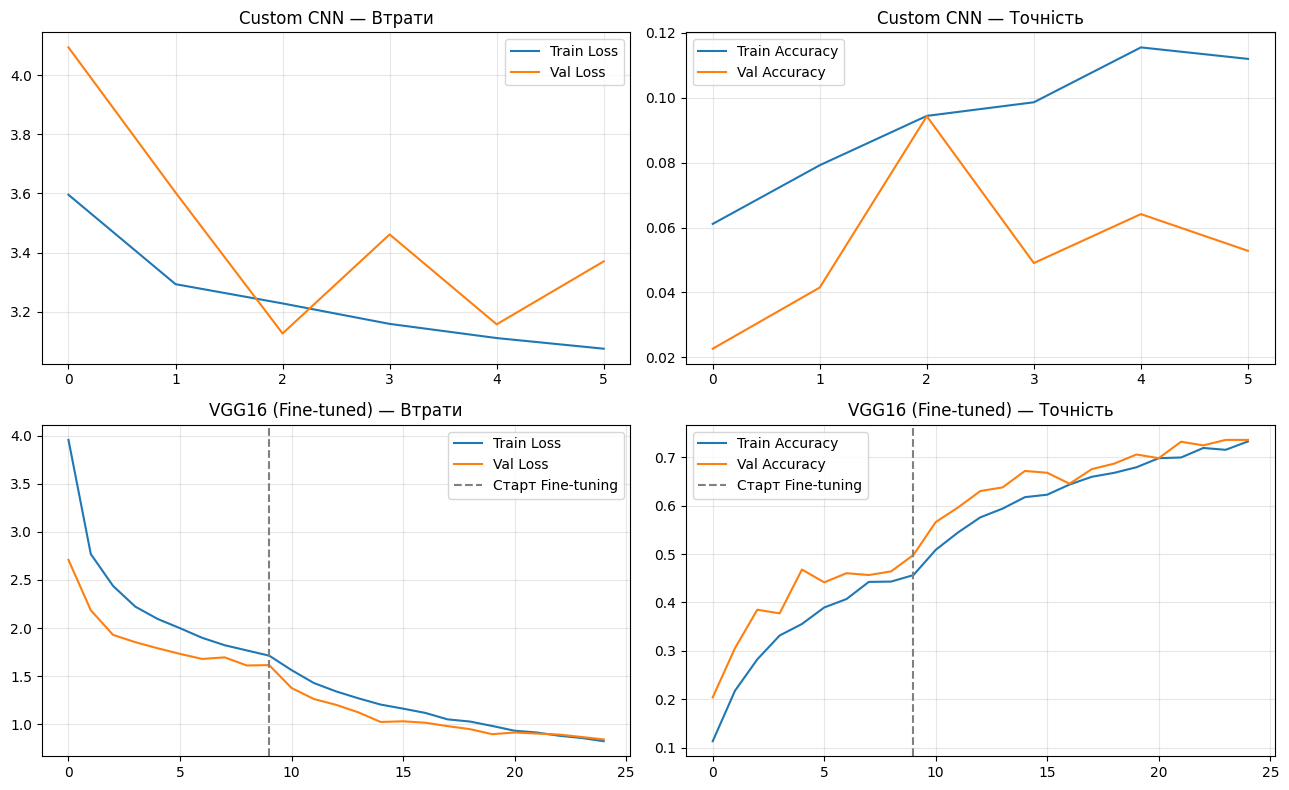

Custom CNN       -> Test Loss: 3.2116 | Test Accuracy: 8.68%
VGG16 Fine-tuned -> Test Loss: 1.1346 | Test Accuracy: 70.94%


In [ ]:
# Об'єднуємо історію двох етапів навчання VGG16 для суцільного графіка
vgg_loss     = history_vgg_head.history["loss"] + history_vgg_ft.history["loss"]
vgg_val_loss = history_vgg_head.history["val_loss"] + history_vgg_ft.history["val_loss"]
vgg_acc      = history_vgg_head.history["accuracy"] + history_vgg_ft.history["accuracy"]
vgg_val_acc  = history_vgg_head.history["val_accuracy"] + history_vgg_ft.history["val_accuracy"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Графіки Custom CNN
axes[0, 0].plot(history_cnn.history["loss"], label="Train Loss")
axes[0, 0].plot(history_cnn.history["val_loss"], label="Val Loss")
axes[0, 0].set_title("Custom CNN — Втрати")
axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(history_cnn.history["accuracy"], label="Train Accuracy")
axes[0, 1].plot(history_cnn.history["val_accuracy"], label="Val Accuracy")
axes[0, 1].set_title("Custom CNN — Точність")
axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

# Графіки VGG16 (Fine-tuned)
axes[1, 0].plot(vgg_loss, label="Train Loss")
axes[1, 0].plot(vgg_val_loss, label="Val Loss")
axes[1, 0].axvline(len(history_vgg_head.history["loss"]) - 1, color="gray", linestyle="--", label="Старт Fine-tuning")
axes[1, 0].set_title("VGG16 (Fine-tuned) — Втрати")
axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(vgg_acc, label="Train Accuracy")
axes[1, 1].plot(vgg_val_acc, label="Val Accuracy")
axes[1, 1].axvline(len(history_vgg_head.history["accuracy"]) - 1, color="gray", linestyle="--", label="Старт Fine-tuning")
axes[1, 1].set_title("VGG16 (Fine-tuned) — Точність")
axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Оцінка обох моделей на тестовій вибірці
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds, verbose=0)
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_ds, verbose=0)

print(f"Custom CNN       -> Test Loss: {cnn_test_loss:.4f} | Test Accuracy: {cnn_test_acc:.2%}")
print(f"VGG16 Fine-tuned -> Test Loss: {vgg_test_loss:.4f} | Test Accuracy: {vgg_test_acc:.2%}")

7. Візуалізація класифікації

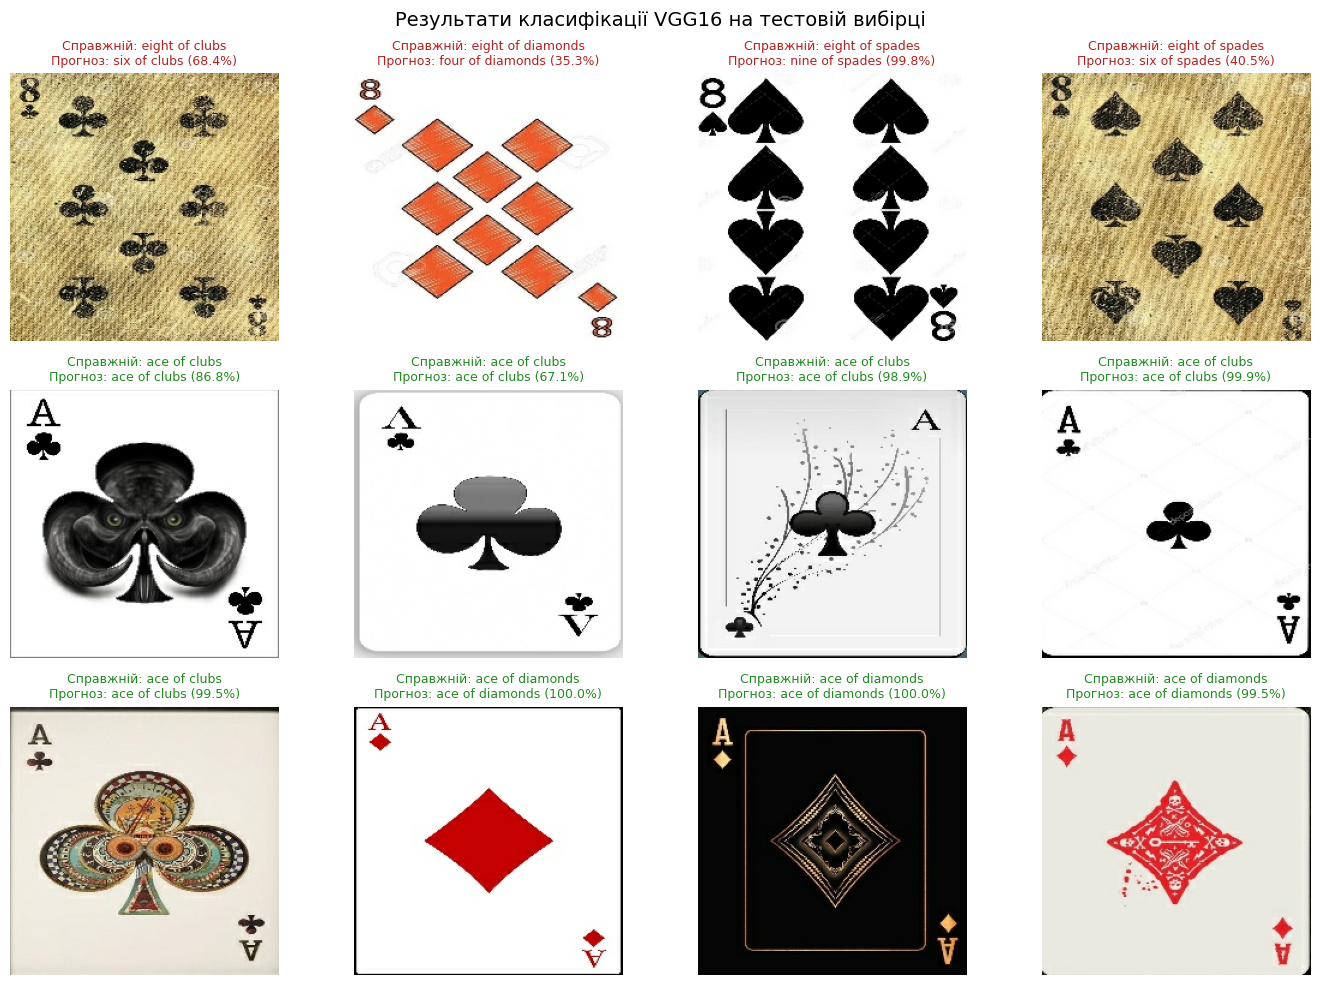

In [ ]:
# Отримуємо всі тестові зображення та мітки для зручної візуалізації
x_test_list, y_test_list = [], []
for imgs, lbls in test_ds:
    x_test_list.append(imgs.numpy().astype("uint8"))
    y_test_list.append(lbls.numpy())

x_test_arr = np.concatenate(x_test_list, axis=0)
y_test_arr = np.concatenate(y_test_list, axis=0)

# Прогноз найкращою моделлю (VGG16)
probs = vgg_model.predict(test_ds, verbose=0)
preds = np.argmax(probs, axis=1)
confs = np.max(probs, axis=1)

# Показуємо 12 тестових зображень
wrong_idx = np.flatnonzero(preds != y_test_arr)
correct_idx = np.flatnonzero(preds == y_test_arr)
sample_idx = list(wrong_idx[:4]) + list(correct_idx[:12 - len(wrong_idx[:4])])

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, idx in zip(axes.flat, sample_idx):
    is_ok = preds[idx] == y_test_arr[idx]
    color = "forestgreen" if is_ok else "firebrick"
    ax.imshow(x_test_arr[idx])
    ax.set_title(
        f"Справжній: {class_names[y_test_arr[idx]]}\n"
        f"Прогноз: {class_names[preds[idx]]} ({confs[idx]:.1%})",
        color=color,
        fontsize=9,
    )
    ax.axis("off")

plt.suptitle("Результати класифікації VGG16 на тестовій вибірці", fontsize=14)
plt.tight_layout()
plt.show()

**Висновки**

У межах дослідження було розв'язано задачу класифікації 53 класів гральних карт із використанням набору даних cards-image-datasetclassification. Первинний аналіз підтвердив рівномірність розподілу класів, а техніки аугментації (масштабування, повороти, корекція контрасту) допомогли мінімізувати перенавчання в умовах обмеженої вибірки. Експериментальне порівняння показало, що попередньо навчена модель VGG16 із поетапним донавчанням (fine-tuning) суттєво перевершує власну легку CNN: залучення готових фільтрів низького та середнього рівнів прискорює збіжність і забезпечує набагато краще розпізнавання дрібних деталей мастей та номіналів. Використання механізму ранньої зупинки (EarlyStopping) дозволило автоматично зберегти найкращі ваги мережі та уникнути її перенавчання. Аналіз візуалізації прогнозів на тестовій вибірці засвідчив високу впевненість моделі на переважній більшості зображень, а нечисленні помилки трапляються переважно при розрізненні візуально схожих старших карт однієї масті.